to do
- define PCA
- save figures as ps or pdf
- make a table specifying which parameters were used to solve the gilmore-akulichev model.
- overlay graphs and spectrums
- plot bar charts for the cluster centres.
- k-means 3d feature space plots
- report k-means parameters, look at how sensitive the algorithm is to each

done
- use smaller fontsize for algorithm, change algorithm to the simpler one without the diamond.
- move pcd data intro to start of methods. merge with existing description of features we expect to find in the signal
- change color and size of nodes in tree graph depending on the label of the node
- include fft of the reconstructions to show which features have been selected
- make a figure with nodes and classification
- define what kind of noise was added. additive white gaussian noise to simulate measurement noise. $20\log{\frac{\mu}{\sigma_{noise}}}=10$ signal to noise ratio
- explain signals used for feature selection. choose wider frequency range, something that reflects the real life uses of ultrasound. go from 0.5 to 2 MHz.

SOMs
- don't use numbers e.g. 2 dimensions, 3 clusters.
- cite classical reference for self-organising maps
- talk about variations on the neural network. refer to paper that uses som's to do feature selection.
- convergence analysis on self-organising maps with starting points, number of signals. see which are the best features in each case.
- decide whether to use SOMs

write-up notes
- don't start (conclusion not summary) with overall
- american english
- use a consistent tense (usually past)
- use commands
- use feature names instead of cluster number
- look at kurtosis to separate measurement noise from broadband
- use (j, k) notation.

by monday 2-3pm
- process c1hat, c5hat (if i have time)
- overlay ffts
- 4 datasets, see if 3 features (energy, kurtosis, crest factor) are enough
- 4 clusters (for noise and harmonics)

- write about standardisation in manuscript

# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")

import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.PCD_data as pcd

import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(rows=1, cols=2)

import numpy as np

### Parameters

Specify parameters for synthetic data and wavelet transform

pac = -20e5
frequency = 1E6             # insonation frequency (Hz)  
fs = 1E9              # sampling rate to generate the time vector  
tstep = 1./fs  
R_init = 1E-6                  # initial bubble radius in meters  
Rdot_init = 0                   # initial bubble's wall velocity in m/s  
r_measure = 500*R_init        

### stable
R_init = -0.1E6                     # the amplitude of the sine wave in Pa  

### transient
pac = -1E6                     # the amplitude of the sine wave in Pa  

In [3]:
# Set sampling rate and noise std
# sampling_rate = 50e6
# signal2noise = 30

# Bubble dynamcis parameters
# R_init = 100e-6
# frequency = 1e6
# pac = -20e5

# Parameters for FFT plot
fft_lim = 5

# Parameters for the wavelet transform
wavelet = "db10"
levels = None  # set to None to use max-level transform
mode = "symmetric"
use_min_entropy = True
min_level = 3

### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [4]:
# # BUBBLE DYNAMICS DATA
# data, t_plot = train.get_data(R_init, frequency, pac, sampling_rate, return_time=True, n_cycles=100)

# # Add noise
# mean_std_noise_ratio = 10 ** (signal2noise / 20)
# std_noise = abs(np.average(data)) / mean_std_noise_ratio
# noise = np.random.normal(0, std_noise, len(data))
# data += noise
# print("std noise:", std_noise)

# PCD DATA
# "5-10", "5-34", "6-12" are the valid arguments for the 1st dataset
# tuples containing the voltage and frequency is used for the 2nd dataset
# e.g. (80, 1) for 80 mVpp, c1hat
frequency = 1.1 * 1e6
data, t_plot = pcd.get_data((80, 5))  # [80, 120, 200, 280], [1, 5, 10]
sampling_rate = 1 / t_plot[1]

/n the data file imported is: /n../docs/PCD data for paper/Test2_HIFU_NoVial_80mVpp_Modf.mat


In [5]:
# Normalise
data = (data - np.average(data)) / np.var(data)
win_func = np.blackman(len(data))
data_windowed = (data * win_func)/np.var(win_func)
signal_length = len(data_windowed)

In [6]:
# Plot generated data
fft_data = np.fft.fft(data_windowed)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]
freq /= frequency
# plot sound wave and fft
fig = make_subplots(rows=3, cols=1)
fig.add_trace( go.Scatter(x=t_plot, y=data_windowed,mode='lines',name='data'),
              row=1,col=1)
fig.add_trace( go.Scatter(x=freq,y=np.log10(np.abs(fft_data)),mode='lines',name='fft - amp'),
              row=2,col=1)
fig.add_trace( go.Scatter(x=freq, y=np.angle(fft_data, deg=True),mode='lines', name = 'fft - phase'),
              row=3,col=1)

fig.update_layout(height=800, width=1200,
                  xaxis1 = dict(title='Time [s]'),
                  xaxis2 = dict(title='Freq [f/f_0]', range=[0, fft_lim]),
                  xaxis3 = dict(title='Freq [f/f_0]', range=[0, fft_lim]),
                  yaxis1 = dict(title='Amplitude [DL]'),
                  yaxis2 = dict(title='Amplitude [dB]'),
                  yaxis3 = dict(title='Amplitude [rad]'))
fig.show()


# ax[0].set_title("Data")
# ax[0].set_xlabel("Time")
# ax[0].set_ylabel("Amplitude")
# ax[0].grid()

# ax[1].plot(
#     freq,
#     np.log10(np.abs(fft_data)),
#     # linefmt="b",
#     # markerfmt=" ",
#     # basefmt="-b",
#     # use_line_collection=True,
# )
# ax[1].set_title("FFT of data - amplitude")
# ax[1].set_xlabel("Frequency [Hz]")
# ax[1].set_ylabel("Amplitude [dB]")
# ax[1].set_xlim(0, fft_lim)
# # ax[1].set_ylim(-10, 1)
# ax[1].grid()

# ax[2].plot(freq, np.angle(fft_data, deg=True))
# ax[2].set_title("FFT of data - phase")
# ax[2].set_xlabel("Frequency [Hz]")
# ax[2].set_ylabel("Phase [rad]")
# ax[2].set_xlim(0, fft_lim)
# ax[2].grid()

Calculating crest factor and energy

Wavelet transform

In [7]:
wpt_df, tr_ob = train.generate_training_data(
    data_windowed, levels, wavelet, mode, 
    include_tr_ob=True, min_entropy=use_min_entropy,
    min_level=min_level
)
# inv.InverseTransform(tr_ob)  # to implement

In [8]:
tr_ob.calc_frequencies(sampling_rate)
# tr_ob.info(leaf_nodes=True)

In [9]:
# ax_df1 = wpt_df.plot.scatter(x='entropy',y='energy',c='black')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.0))
# ax_df2.spines['right'].set_edgecolor('red')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='kurtosis',c='red')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.15))
# ax_df2.spines['right'].set_edgecolor('green')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='skewness',c='green')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.3))
# ax_df2.spines['right'].set_edgecolor('cyan')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='crest factor',c='cyan')

In [10]:
# ax_df1 = wpt_df.plot.scatter(x='kurtosis',y='skewness',c='black')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.0))
# ax_df2.spines['right'].set_edgecolor('red')
# wpt_df.plot.scatter(ax=ax_df2, x='kurtosis',y='crest factor',c='red')

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

In [11]:
# tr_ob.calc_frequencies(sampling_rate)
# plot.heisenberg(tr_ob, max(t_plot))

In [12]:
# wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [13]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, labels, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)


In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# training k-means algorithm
kmeans_params = {"init":"k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"elkan",
    }

def train_k_means(wpt_df, classifying_metrics, *, no_clusters=None, use_pca=False):
    """
    Trains a k-means algorithm based on a set of training data given by wpt_df and classifying metrics
    no_clusters can be kept at None to choose an optimal number of clusters by silhouette score.
    use_pca can be set to True to apply pca to the normalised data set before training the algorithm.

    """
    data_train = wpt_df[classifying_metrics]

    scaler = StandardScaler()
    data_train_normalised = scaler.fit_transform(data_train)

    if use_pca is True:
        pca = PCA(n_components=3)
        data_train_normalised = pca.fit_transform(data_train_normalised)    

    if no_clusters is not None:
        kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
        labels = kmeans.fit_predict(data_train_normalised)
    else:
        algorithms = []
        for no_clusters in range(3, 6):
            kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
            labels = kmeans.fit_predict(data_train_normalised)
            silhouette_score = metrics.silhouette_score(data_train_normalised, labels)
            algorithms.append((silhouette_score, kmeans, labels))
        i = max(algorithms, key=lambda x: x[0])
        _, kmeans, labels = i

    centers = kmeans.cluster_centers_
    if use_pca is False:
        centers = scaler.inverse_transform(centers)
        return data_train, labels, data_train_normalised, centers, scaler, kmeans
    if use_pca is True:
        centers = scaler.inverse_transform(pca.inverse_transform(centers))
        return data_train, labels, data_train_normalised, centers, scaler, kmeans, pca


### K-means without PCA

In [15]:
# training data
classifying_metrics = [
    "average energy",
    "kurtosis",
    # "crest factor",
    # "log average energy",
    # "level entropy",
    "spectral entropy"
]
# Set to None to select optimal number of clusters by silhouette score
no_clusters = None
data_train, labels, data_train_normalised, centers, _, kmeans = train_k_means(
    wpt_df, classifying_metrics, no_clusters=no_clusters
)

In [16]:
cluster_ids, cluster_sizes = np.unique(labels, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [ 2 15 19  1  8]
cluster IDs: [0 1 2 3 4]


In [17]:
# fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data', n_runs=100)

3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [18]:
data_train_predict_pca, labels_pca, _, centers_pca, scaler, kmeans_pca, pca = train_k_means(
    wpt_df, classifying_metrics, no_clusters=no_clusters, use_pca=True
)

In [19]:
kmeans_pca.cluster_centers_

array([[-6.81367073e-01, -6.44602666e-01,  4.40985661e-01],
       [ 6.85485963e-01, -1.80010996e-01, -8.06227040e-01],
       [ 5.67480685e+00,  2.49671663e-01,  3.70666430e+00],
       [-1.50478669e+00,  2.96679752e+00,  9.63079641e-01],
       [-1.93566235e-04,  1.09554361e+00, -2.39768191e-01]])

In [20]:
# PC_df = pd.DataFrame(data = pca.transform(data_train_normalised)
#              , columns = ['principal component 1', 'principal component 2', 'principal component 3'])

# ax_pca_df1 = PC_df.plot.scatter(x='principal component 1',y='principal component 2', c='black')

# ax_pca_df2 = ax_pca_df1.twinx()
# ax_pca_df2.spines['right'].set_position(('axes', 1.0))
# ax_pca_df2.spines['right'].set_edgecolor('red')
# PC_df.plot.scatter(ax=ax_pca_df2, x='principal component 1',y='principal component 3', c='red')


### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

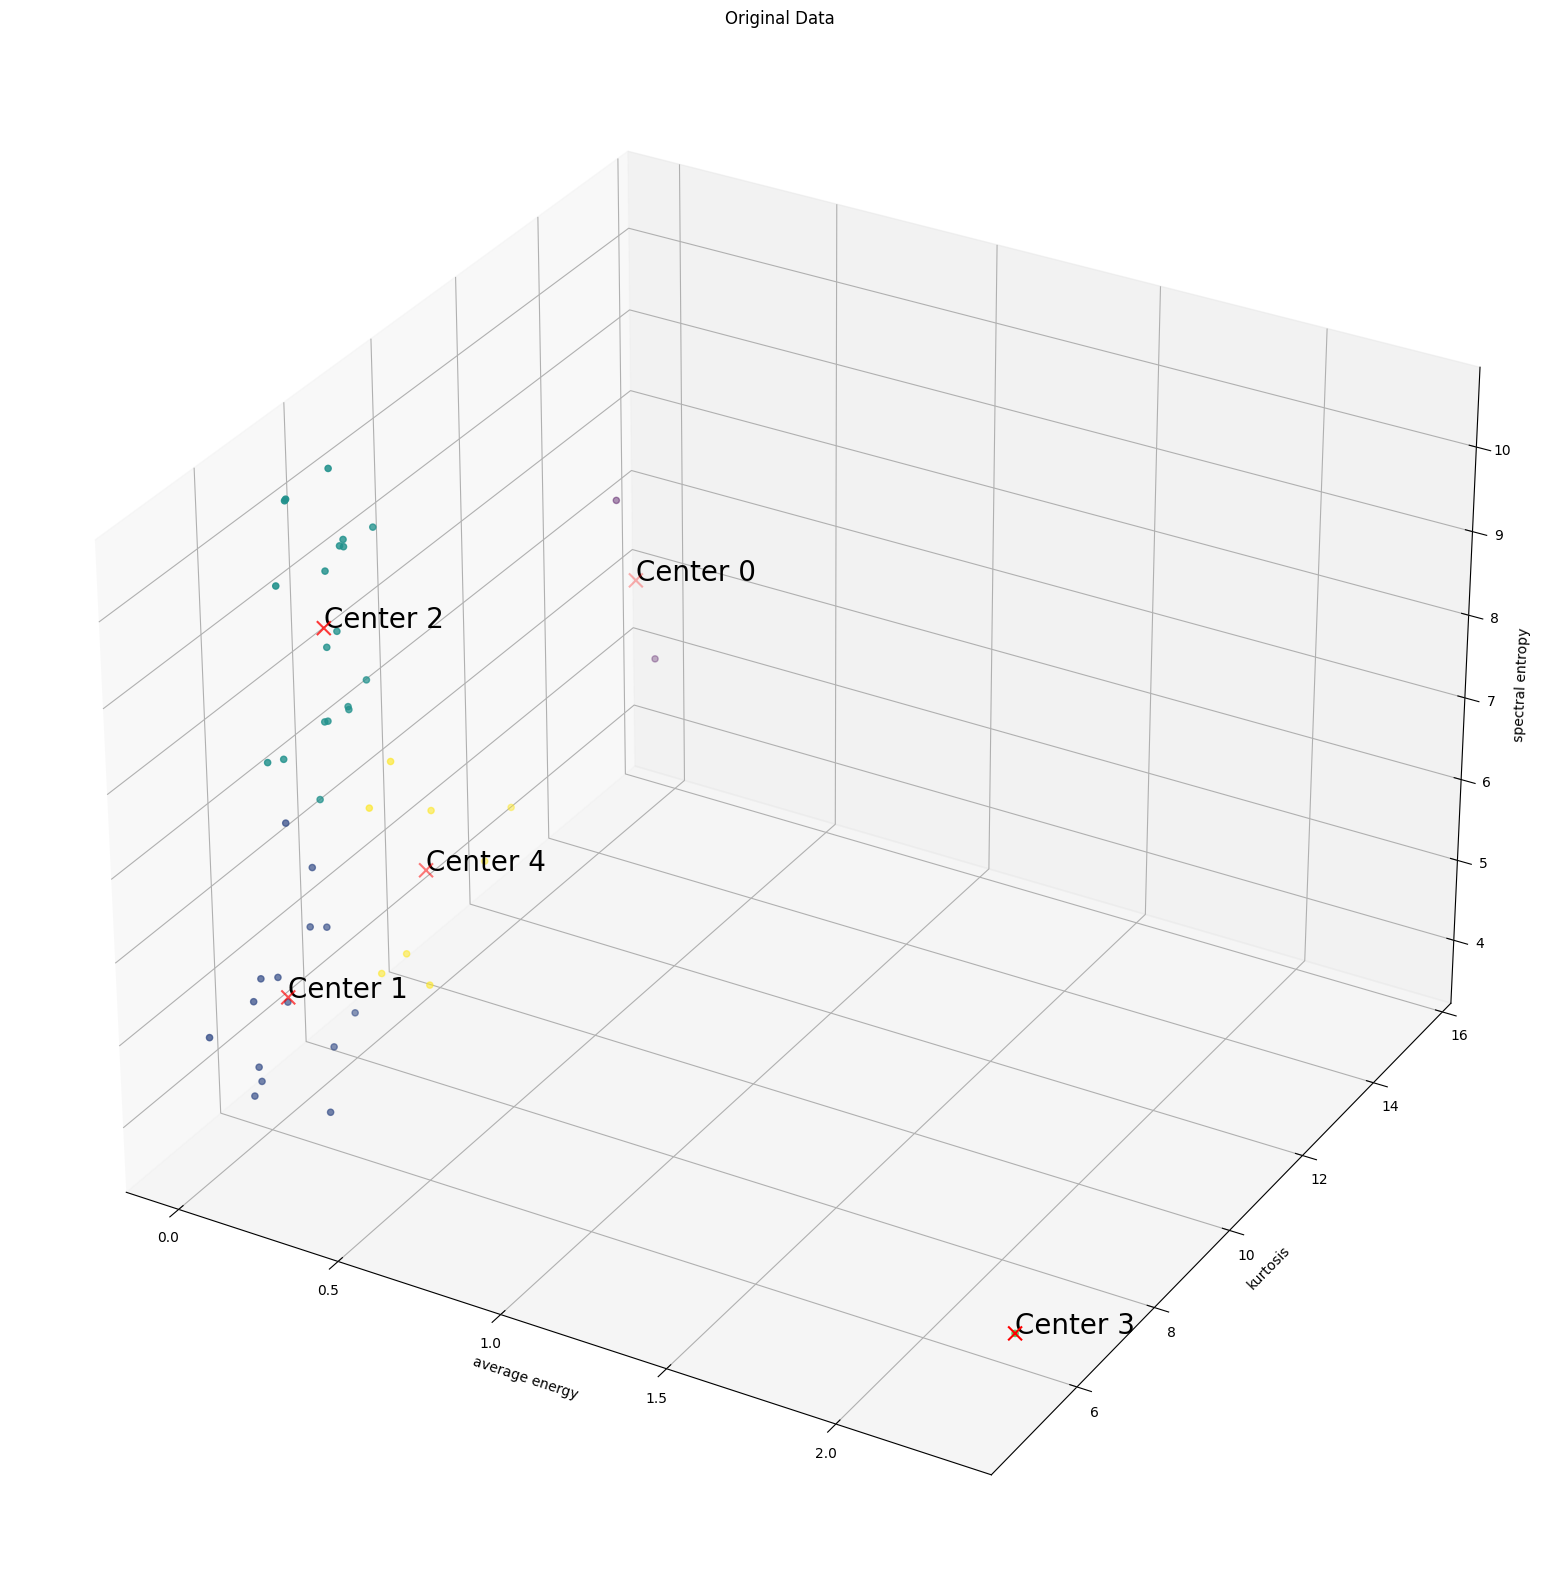

In [21]:
# Define data and titles for each subplot
data_sets = [
    (data_train.values.tolist(), centers, labels, "Original Data"),
    # (data_train.values.tolist(), centers_pca, labels_pca, "PCA Data")
]

# Create separate figures for each subplot
for data_scatter, centers_scatter, labels_scatter, title in data_sets:
    fig = plt.figure(figsize=(20, 20))
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=labels_scatter
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    for j, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {j}', color='black', fontsize=20)

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(title)

# Show the figures
plt.show()


measurement noise:
- kurtosis = 3

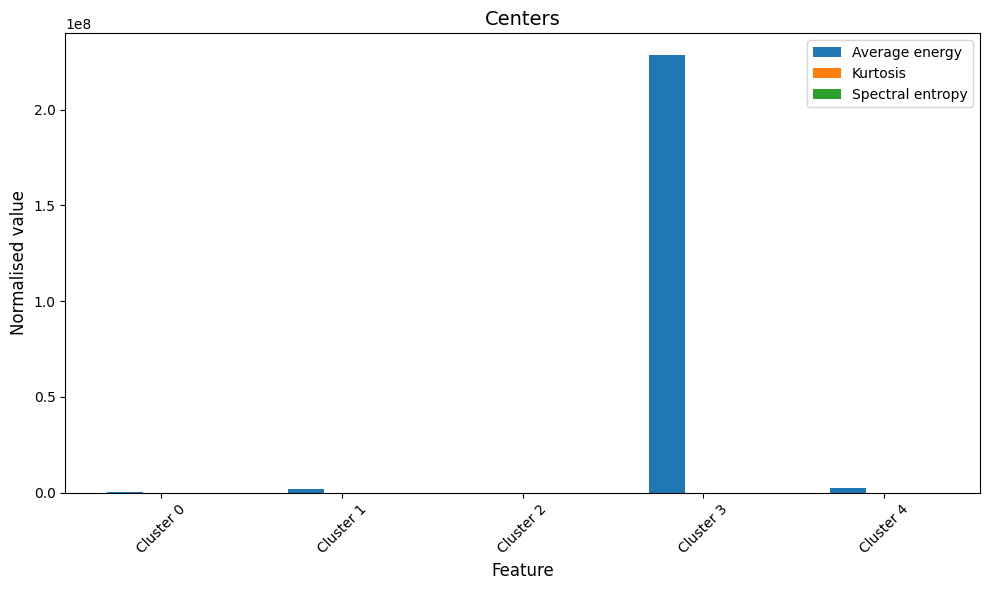

In [22]:
# Swap legend and x-axis?
n_clusters = centers.shape[0]
fig, ax = plt.subplots(figsize=(10, 6))

width = 0.2
x = np.arange(n_clusters)

for i, feature in enumerate(centers.T): #StandardScaler().fit_transform(centers).T):
    ax.bar(
        x + i * width, feature, # - min(feature) + 1, 
        width, label=f"{classifying_metrics[i]}".capitalize()
    )

ax.set_ylabel("Normalised value", fontsize=12)
ax.set_xlabel("Feature", fontsize=12)
ax.set_title("Centers", fontsize=14)
plt.xticks(
    x + i * width / 2, [f"Cluster {i}" for i in range(n_clusters)], 
    rotation=45, fontsize=10
)
plt.yticks(fontsize=10)

ax.legend(loc='best', fontsize=10)
plt.tight_layout()

plt.show()


In [23]:
centers

array([[2.98879796e+05, 1.50120885e+01, 6.27551089e+00],
       [2.00869001e+06, 6.32152266e+00, 4.72558517e+00],
       [1.50131634e+04, 7.54244528e+00, 8.64326509e+00],
       [2.28382649e+08, 5.86590872e+00, 3.69642675e+00],
       [2.30900113e+06, 9.56520216e+00, 4.89666384e+00]])

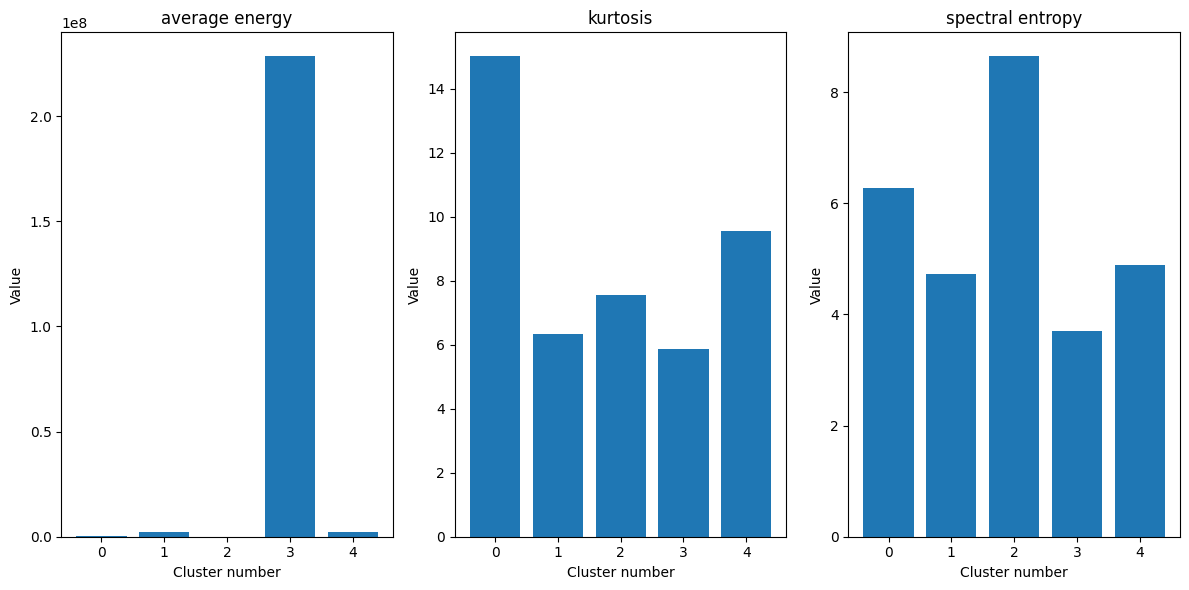

In [24]:
fig, ax = plt.subplots(1, len(classifying_metrics), figsize=(12, 6))
for i in range(len(classifying_metrics)):
    ax[i].bar(np.arange(n_clusters), centers[:, i])
    ax[i].set_title(f"{classifying_metrics[i]}")
    ax[i].set_xlabel("Cluster number")
    ax[i].set_ylabel("Value")
plt.tight_layout()
plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

In [25]:
# display(tr_ob.info(leaf_nodes=True))  # natural order
# labels  # natural order

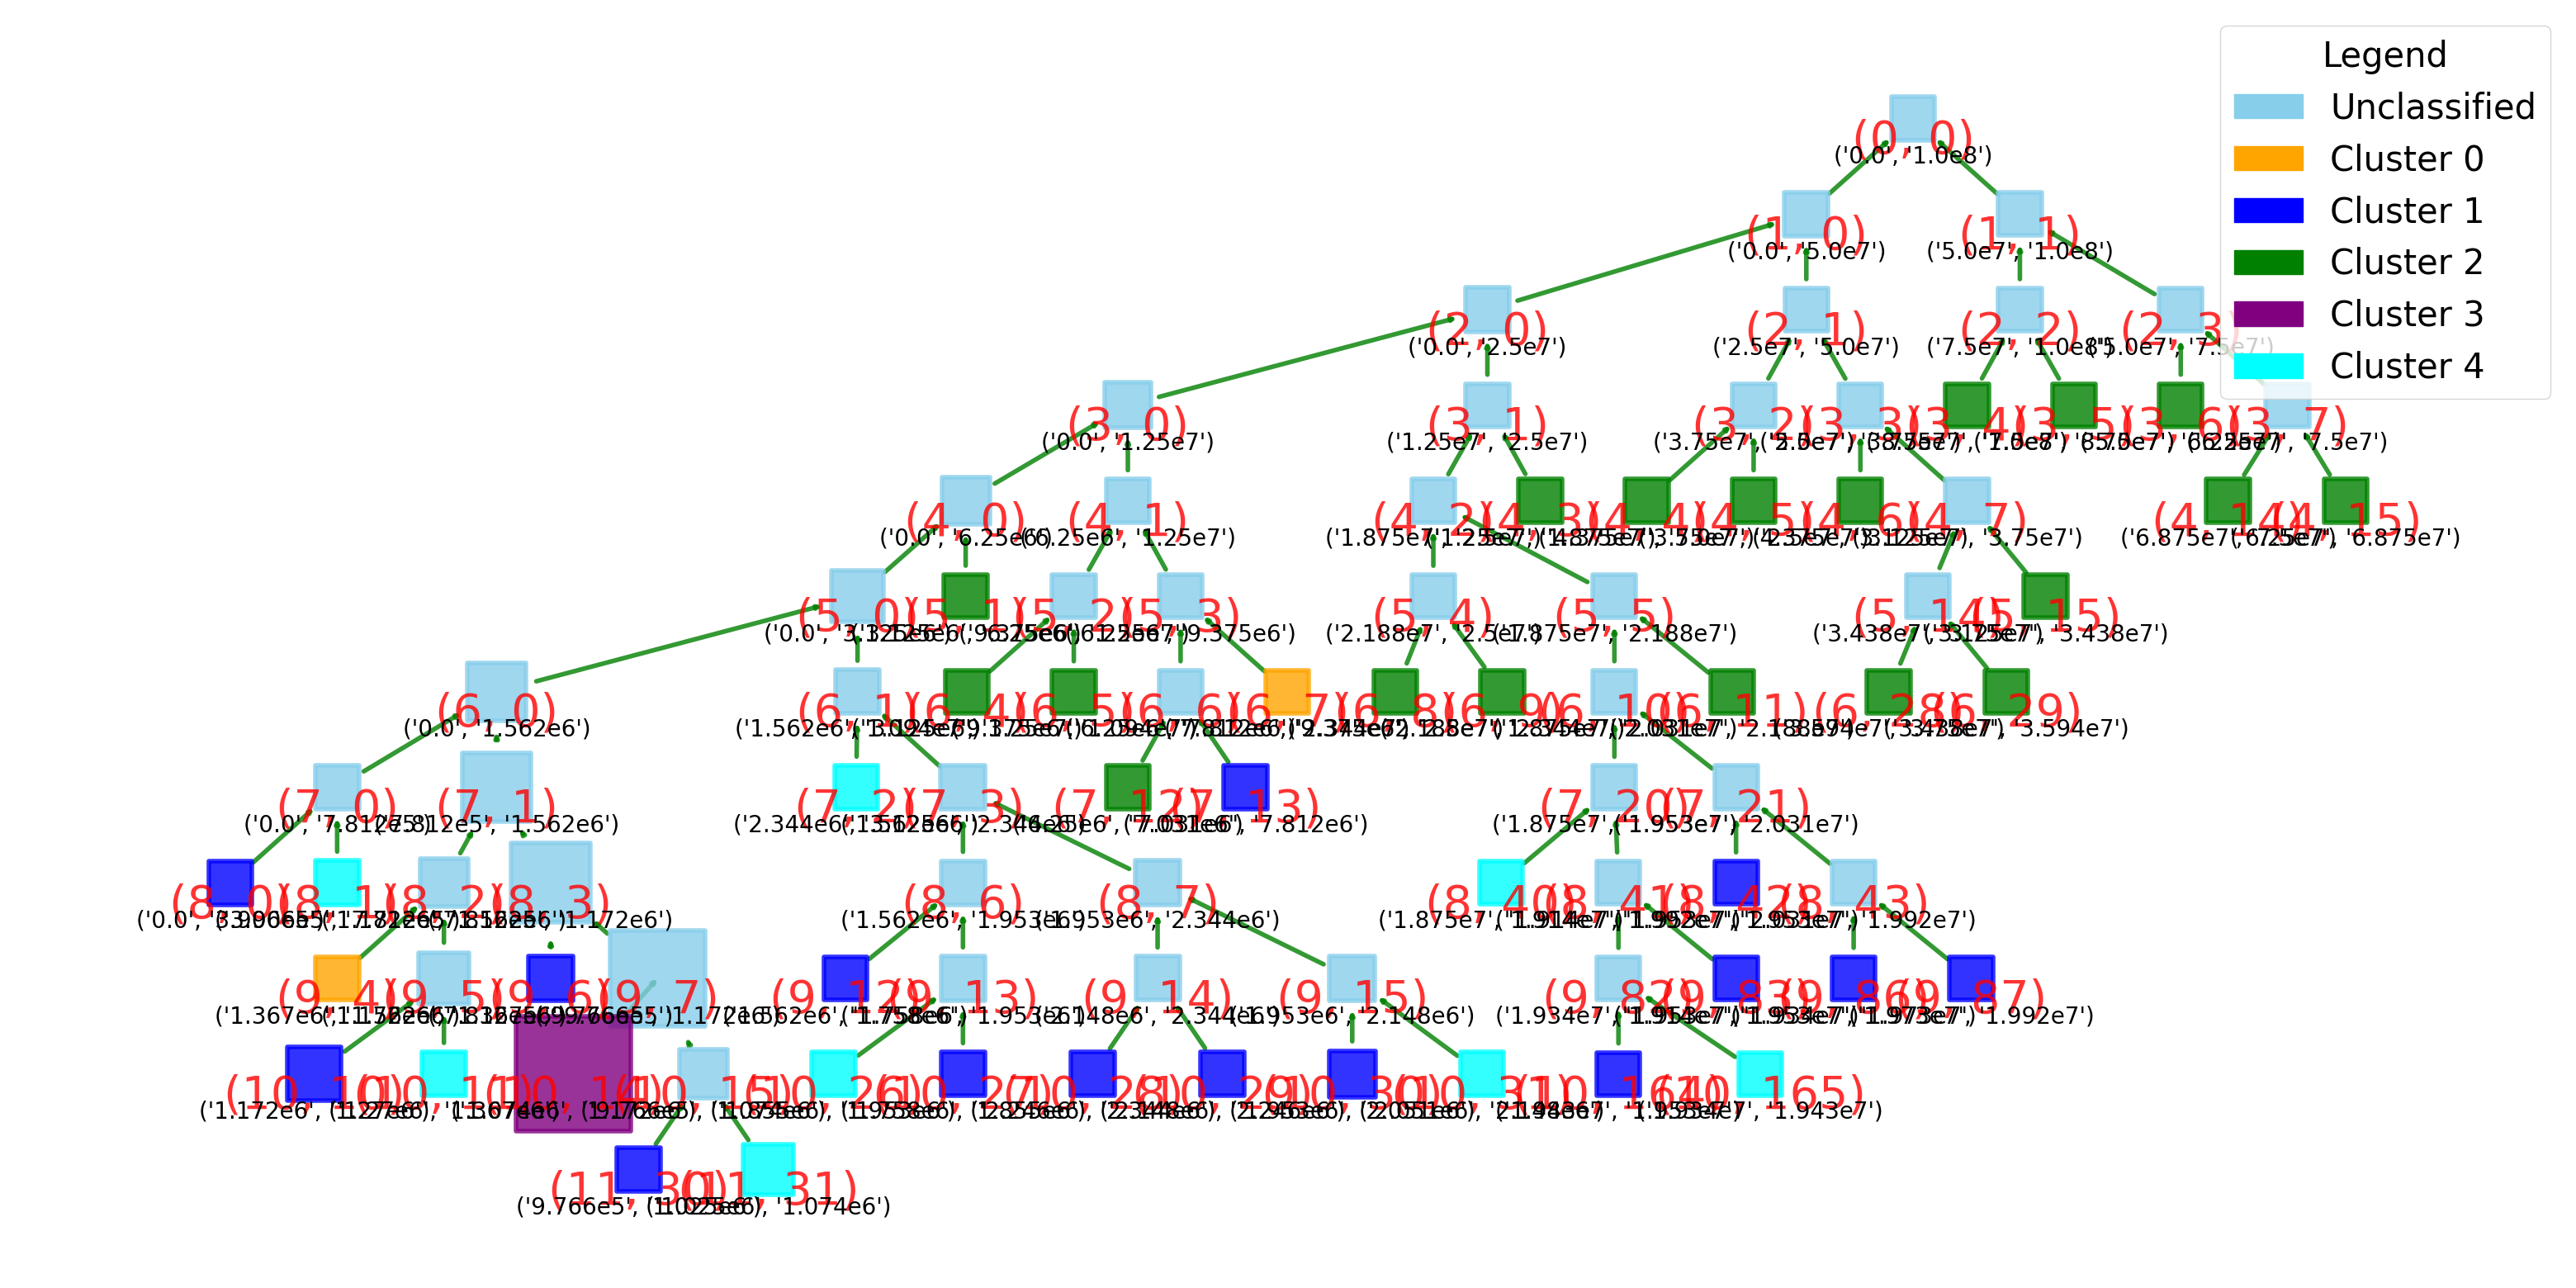

In [26]:
tr_ob.plot_tree(node_size="average energy", node_colour=list(labels))

Reconstructed nodes by group:


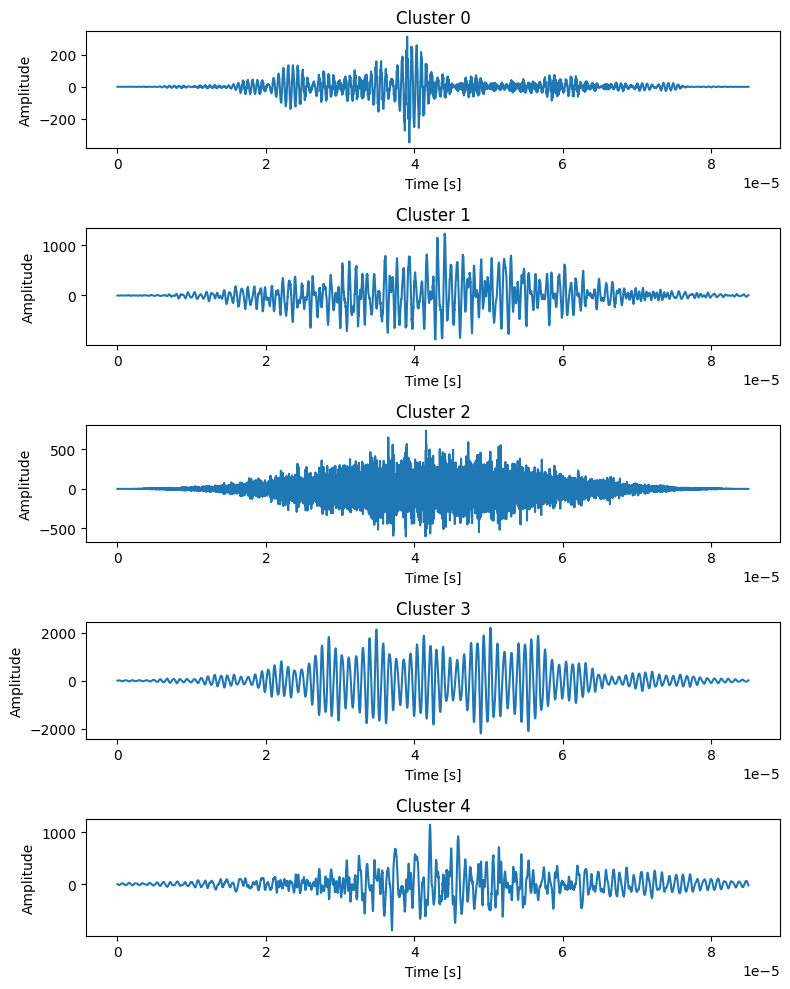

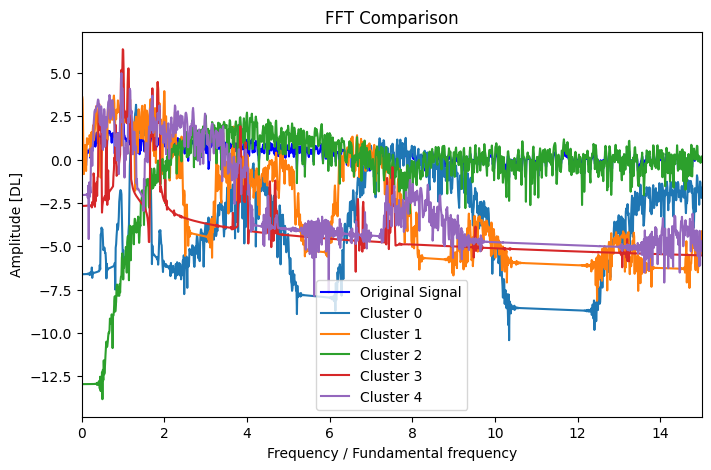

In [27]:
plot.plot_reconstructions_by_group(tr_ob, labels, no_clusters, t_plot)

# set clusters to None to plot all of them
plot.plot_fft_by_group(
    tr_ob, labels, no_clusters, sampling_rate, 
    clusters=None, xlim=15, fundamental_freq=frequency
)

pca results

In [28]:
# plot pca results
# plot.plot_reconstructions_by_group(tr_ob, labels_pca, no_clusters, t_plot, sampling_rate)

separately plot reconstructions of all nodes belonging to selected clusters

(87500000.0, 100000000.0)


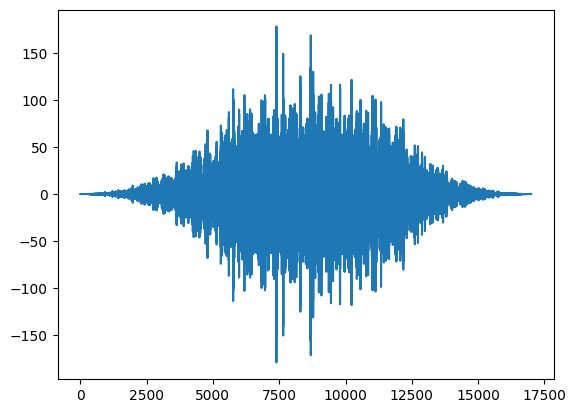

(75000000.0, 87500000.0)


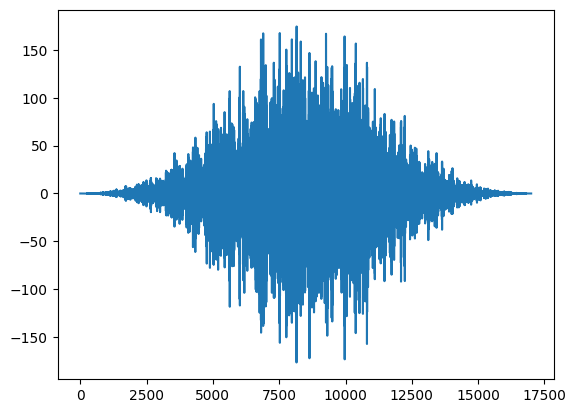

(50000000.0, 62500000.0)


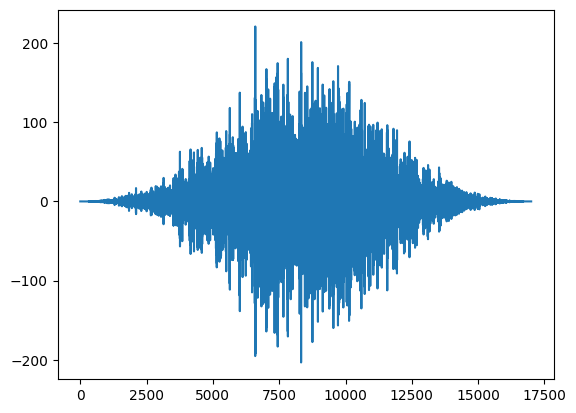

(12500000.0, 18750000.0)


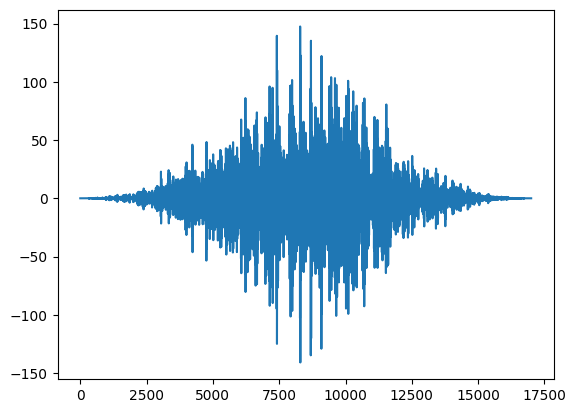

(43750000.0, 50000000.0)


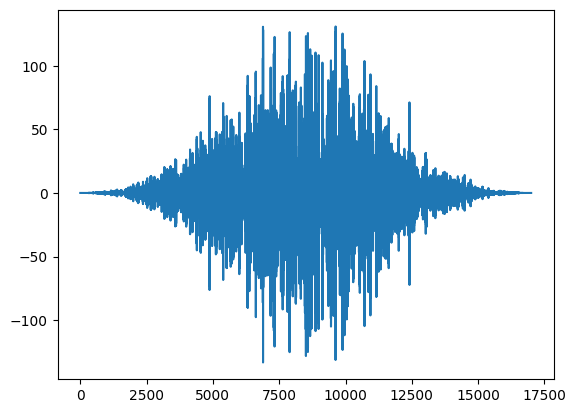

(37500000.0, 43750000.0)


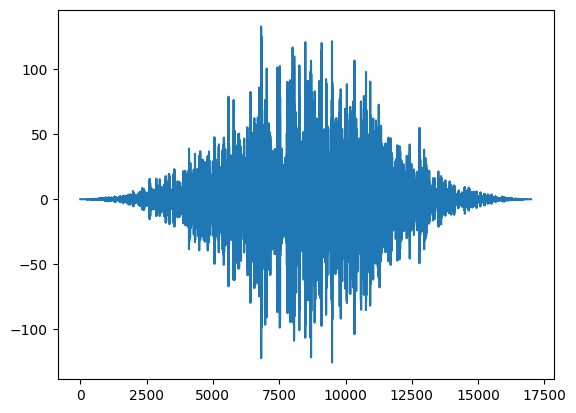

(25000000.0, 31250000.0)


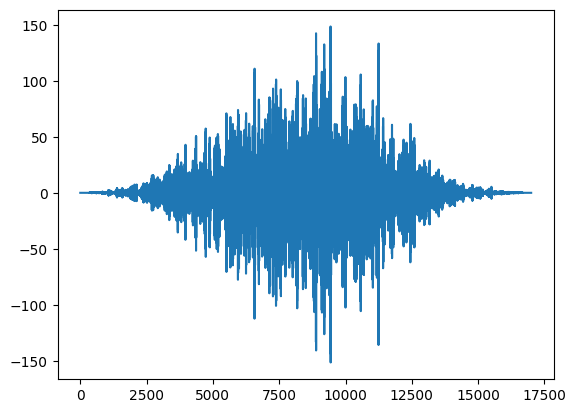

(68750000.0, 75000000.0)


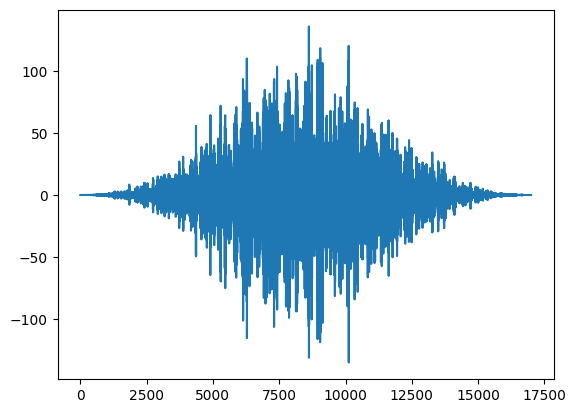

(62500000.0, 68750000.0)


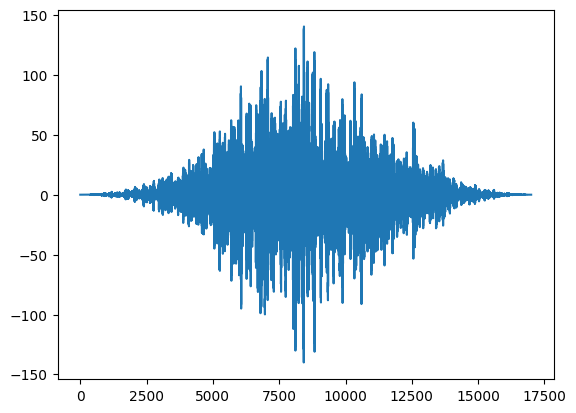

(3125000.0, 6250000.0)


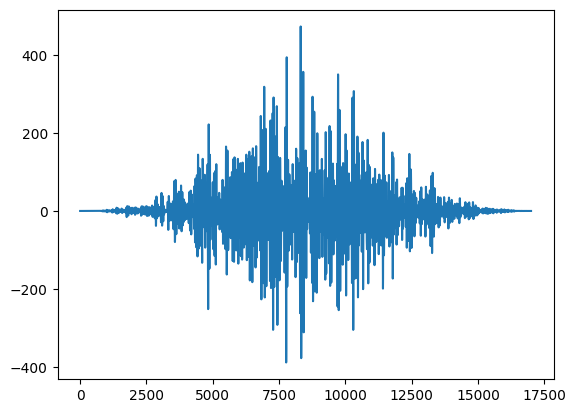

(31250000.0, 34375000.0)


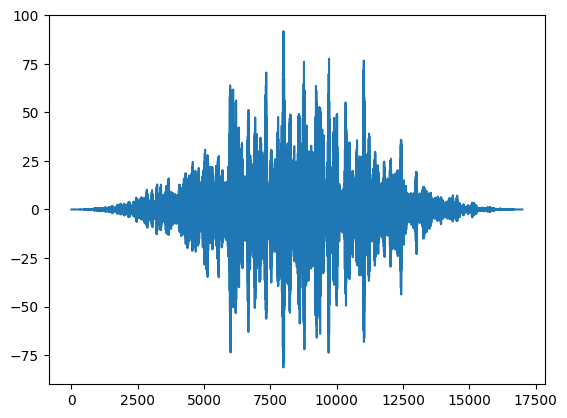

(10937500.0, 12500000.0)


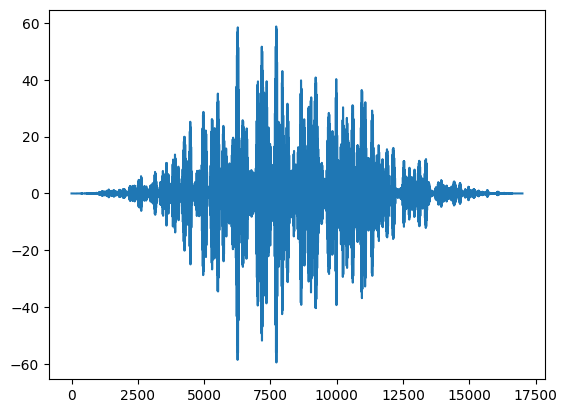

(9375000.0, 10937500.0)


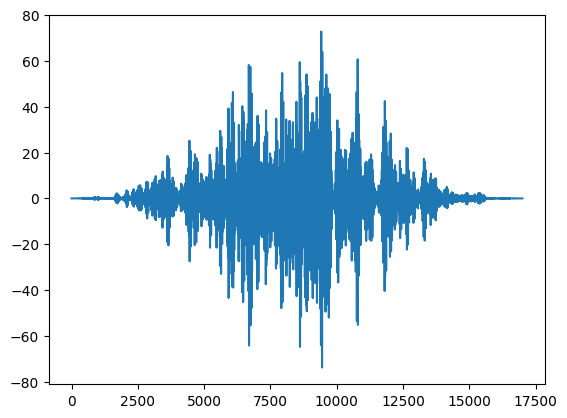

(23437500.0, 25000000.0)


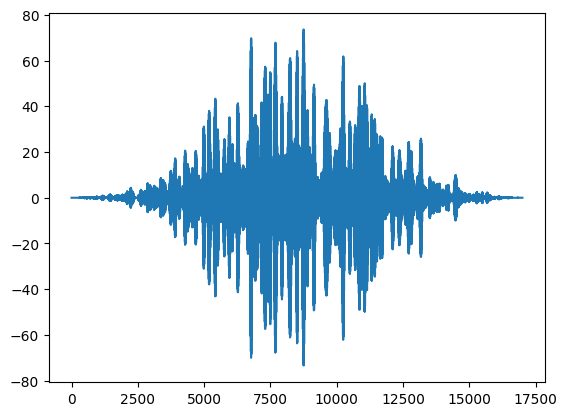

(21875000.0, 23437500.0)


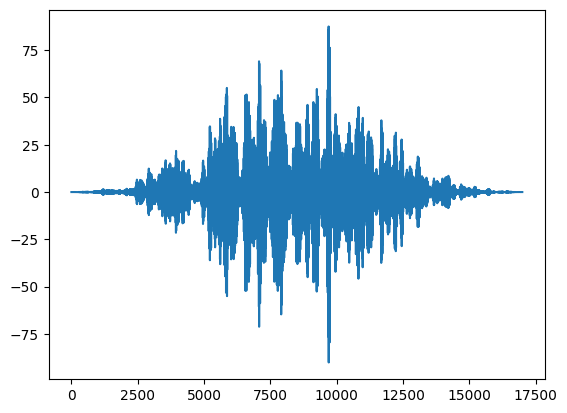

(20312500.0, 21875000.0)


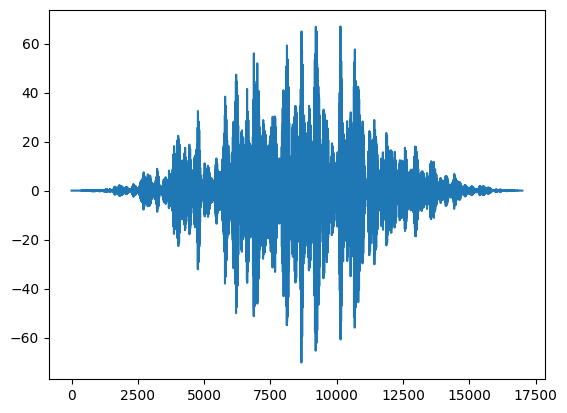

(35937500.0, 37500000.0)


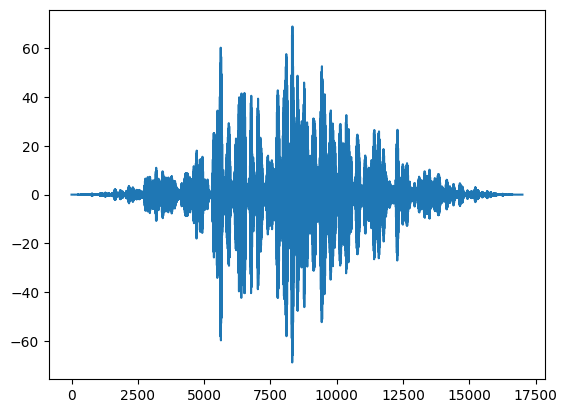

(34375000.0, 35937500.0)


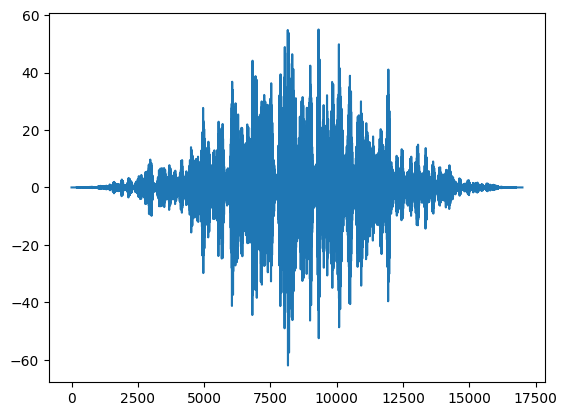

(6250000.0, 7031250.0)


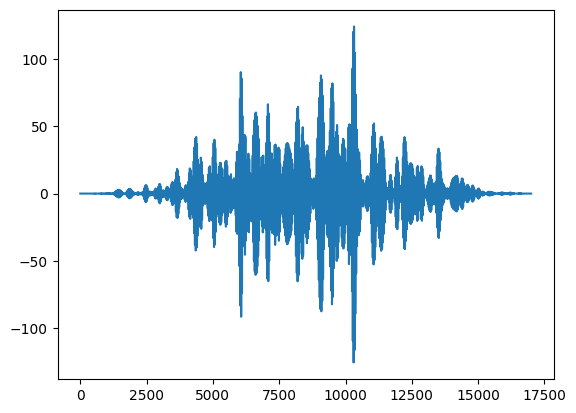

In [29]:
import wavelet_transform.wpt.inverse_transform as inv
# Add number to list to plot reconstructions of all nodes belonging to the cluster

plot_centres = [2]
for i, (node, assignment) in enumerate(zip(tr_ob.get_leaf_nodes(), labels)):
    if assignment in plot_centres:
        # print(node.crest_factor)
        print(node.frequency_range)
        rec = inv.inv_dwpt(tr_ob, node.level, nodes=node)
        plt.plot(rec)
        plt.show()

In [30]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["average energy"] > THR_Factor * np.max(data_train["average energy"])
]
harmonics_data = harmonics_data.sort_values(by="average energy", ascending=False)

In [31]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["crest factor"] > THR_Factor * np.max(data_train["crest factor"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

KeyError: 'crest factor'

In [ ]:
print(len(harmonics_data["energy"]))
harmonics_data["frequency range"].values.tolist()

In [ ]:
harmonics_data.plot.bar()

In [ ]:
transient_data.plot.bar()
plt.show()